# Lab 11 — Layer-wise probing of BERT with logistic regression (SentEval probing tasks)

**Tasks** (SentEval probing data, `data/probing/`): sentence length (`sentence_length.txt`), bigram shift
(`bigram_shift.txt`), and subject number (`subj_number.txt`).

**Protocol**
1. Pool each file's own train/dev/test splits and remove duplicate sentences, so no sentence can cross train and test.
2. Sample a **class-balanced** set of **50,000** sentences per task. Sentence length has six classes, so the per-class
   count is 8,330 (49,980 total); 50,000 is not divisible by 6. The two binary tasks use 25,000 per class.
   Each per-class count is divisible by 10, so the 90:10 split is exact.
3. Split **90:10, stratified** by class.
4. Encode every sentence with **BERT-base-uncased** (12 encoder layers) and take the **mean of the word-piece vectors
   of the sentence only** (padding masked out, and `[CLS]`/`[SEP]` excluded). Layers 1–12 are the 12 models; layer 0
   (the input embeddings) is reported separately as a reference for how much is contextual. The pooling choice was
   tested: including `[CLS]`/`[SEP]` lets sentence length leak into the mean (see §3 and the ablation in §5).
5. Train one **standardised, multinomial logistic regression** per layer, with `max_iter` raised and convergence
   recorded for every fit.

**Reference numbers:** the assignment links arXiv:1803.05449, which is the SentEval *toolkit* paper. The probing
paper is **arXiv:1805.01070** ("What you can cram into a single vector", Conneau et al. 2018). Its **Table 4**
reports logistic-regression probing accuracies, so that table is the comparison used in §5.

## 0. Setup and stages

In [1]:
import json, os, time, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
from joblib import Parallel, delayed

STAGE = os.environ.get("LAB11_STAGE", "all")          # all | data | extract | probe
DO_DATA = STAGE in ("all", "data")
DO_EXTRACT = STAGE in ("all", "extract")
DO_PROBE = STAGE in ("all", "probe")

SEED = 42
N_PER_TASK_TOTAL = 50000
TRAIN_FRAC = 0.9
MODEL_ID = "bert-base-uncased"
RAW_DIR = "data/raw"
OUT = "data"
INCLUDE_SPECIAL = False                       # [CLS]/[SEP] in the mean? see §3 for why this is False
TAG = "incl_special" if INCLUDE_SPECIAL else "excl_special"
FEAT_DIR = f"{OUT}/features_{TAG}"
RESULTS_PATH = f"{OUT}/probe_results_{TAG}.json"
os.makedirs(FEAT_DIR, exist_ok=True)

TASKS = {
    "sentence_length": {"file": "sentence_length.txt", "labels": ["0", "1", "2", "3", "4", "5"], "per_class": 8330},
    "bigram_shift":    {"file": "bigram_shift.txt",    "labels": ["I", "O"],                 "per_class": 25000},
    "subj_number":     {"file": "subj_number.txt",     "labels": ["NN", "NNS"],              "per_class": 25000},
}
print("stage:", STAGE)


stage: all


## 1. Load, deduplicate, sample, and split (90:10, stratified)

The raw files are the SentEval probing data (tab-separated: `split`, `label`, `sentence`). Each sentence
string appears once in the pool, so the same sentence cannot end up in both train and test.

In [2]:
def load_pool(path):
    rows = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip("\n").split("\t", 2)
            if len(parts) == 3:
                rows.append((parts[1], parts[2]))
    pool = pd.DataFrame(rows, columns=["label", "sentence"]).drop_duplicates(subset="sentence", keep="first")
    return pool.reset_index(drop=True)

split_summary = {}
if DO_DATA:
    rng = np.random.default_rng(SEED)
    for task, spec in TASKS.items():
        pool = load_pool(f"{RAW_DIR}/{spec['file']}")
        parts = []
        for lab in spec["labels"]:
            sub = pool[pool.label == lab]
            if len(sub) < spec["per_class"]:
                raise ValueError(f"{task}: class {lab} has only {len(sub)} sentences")
            chosen = sub.sample(n=spec["per_class"], random_state=int(rng.integers(1 << 31)))
            n_train = int(round(TRAIN_FRAC * spec["per_class"]))
            chosen = chosen.reset_index(drop=True)
            chosen["split"] = ["train"] * n_train + ["test"] * (spec["per_class"] - n_train)
            parts.append(chosen)
        data = pd.concat(parts).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
        data.to_csv(f"{OUT}/{task}_split.csv", index=False)
        split_summary[task] = {
            "pool_after_dedup": int(len(pool)),
            "total": int(len(data)),
            "train": int((data.split == "train").sum()),
            "test": int((data.split == "test").sum()),
            "per_class_total": spec["per_class"],
        }
    json.dump(split_summary, open(f"{OUT}/split_summary.json", "w"), indent=2)
else:
    split_summary = json.load(open(f"{OUT}/split_summary.json"))
pd.DataFrame(split_summary).T


,pool_after_dedup,total,train,test,per_class_total
sentence_length,118904,49980,44982,4998,8330
bigram_shift,119631,50000,45000,5000,25000
subj_number,119236,50000,45000,5000,25000


In [3]:
splits = {task: pd.read_csv(f"{OUT}/{task}_split.csv", keep_default_na=False, dtype={"label": str, "sentence": str, "split": str})
          for task in TASKS}
for task, df in splits.items():
    train_sents = set(df.loc[df.split == "train", "sentence"])
    test_sents = set(df.loc[df.split == "test", "sentence"])
    overlap = len(train_sents & test_sents)
    assert overlap == 0, f"{task}: {overlap} sentences in both train and test"
    ct = pd.crosstab(df.label, df.split)
    print(f"== {task}: train/test sentence overlap = {overlap}; class balance:")
    print(ct.to_string(), "\n")


== sentence_length: train/test sentence overlap = 0; class balance:
split  test  train
label             
0       833   7497
1       833   7497
2       833   7497
3       833   7497
4       833   7497
5       833   7497 

== bigram_shift: train/test sentence overlap = 0; class balance:
split  test  train
label             
I      2500  22500
O      2500  22500 

== subj_number: train/test sentence overlap = 0; class balance:
split  test  train
label             
NN     2500  22500
NNS    2500  22500 



## 2. Tokenisation: measure lengths before fixing `max_length`

Truncation can destroy the signal. In sentence-length probing, the longest class would be cut back to the
same length as the one before it, and accuracy would fall for a reason unrelated to BERT. So the length
distribution per class is measured first, `max_length` is chosen above the largest sentence, and zero
truncation is asserted.

In [4]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(MODEL_ID)

len_rows = []
for task, df in splits.items():
    lens = np.array([len(x) for x in tok(df.sentence.tolist(), add_special_tokens=True)["input_ids"]])
    df = df.assign(n_wordpieces=lens)
    for lab, sub in df.groupby("label"):
        len_rows.append({"task": task, "label": lab, "n": len(sub), "median": float(sub.n_wordpieces.median()),
                         "max": int(sub.n_wordpieces.max())})
len_df = pd.DataFrame(len_rows)
len_df


,task,label,n,median,max
0,sentence_length,0,8330,9.0,19
1,sentence_length,1,8330,13.0,22
2,sentence_length,2,8330,17.0,29
3,sentence_length,3,8330,21.0,31
4,sentence_length,4,8330,26.0,45
5,sentence_length,5,8330,30.0,62
6,bigram_shift,I,25000,16.0,51
7,bigram_shift,O,25000,16.0,70
8,subj_number,NN,25000,16.0,39
9,subj_number,NNS,25000,16.0,41


In [5]:
MAX_LEN = int(np.ceil((int(len_df["max"].max()) + 1) / 8) * 8)      # multiple of 8, strictly above the longest sentence
for task, df in splits.items():
    n_long = int((np.array([len(x) for x in tok(df.sentence.tolist(), add_special_tokens=True)["input_ids"]]) > MAX_LEN).sum())
    assert n_long == 0, f"{task}: {n_long} sentences would be truncated at max_length={MAX_LEN}"
print("max_length =", MAX_LEN, "| zero truncation in all tasks")


max_length = 72 | zero truncation in all tasks


## 3. Feature extraction: mean-pooled hidden states, one file per layer

`output_hidden_states=True` gives 13 tensors: index 0 is the input embedding output, indices 1–12 are the
encoder layers. Each sentence is represented by the **mean over its word-piece tokens** at each layer:
`sum(hidden × mask) / sum(mask)`, where `mask` removes padding *and* `[CLS]`/`[SEP]`.

**Why `[CLS]`/`[SEP]` are excluded.** Including them adds a fixed vector with weight 2/n to the mean, where n is the sentence length, so the pooled vector carries a direct length cue. On word embeddings alone (no positions, no transformer), that cue is large: 91.8% sentence-length accuracy with the special tokens and 55.9% without them. In the full model the effect is small (at most 1.7 points, §5), because positional information dominates. Both runs are reported. Features are stored as float16, one `.npy` file per layer, so the 13 layers are never held in RAM together.

The device is the GPU when one is free. Feature extraction must not run while another large model shares
the 4 GB card.

In [6]:
import torch
from transformers import AutoModel

DEVICE = torch.device(os.environ.get("LAB11_DEVICE", "cuda" if torch.cuda.is_available() else "cpu"))
print("extraction device:", DEVICE)

def feat_path(task, layer):
    return f"{FEAT_DIR}/{task}/layer{layer:02d}.npy"

if DO_EXTRACT:
    bert = AutoModel.from_pretrained(MODEL_ID).to(DEVICE).eval()
    for task, df in splits.items():
        os.makedirs(f"{FEAT_DIR}/{task}", exist_ok=True)
        if all(os.path.exists(feat_path(task, l)) for l in range(13)):
            print(task, "features already extracted; skipping")
            continue
        n = len(df)
        mmaps = [np.lib.format.open_memmap(feat_path(task, l), mode="w+", dtype=np.float16, shape=(n, bert.config.hidden_size))
                 for l in range(13)]
        sentences = df.sentence.tolist()
        t0 = time.time()
        with torch.no_grad():
            for start in range(0, n, 128):
                batch = tok(sentences[start:start + 128], padding=True, truncation=False, max_length=MAX_LEN,
                            return_tensors="pt").to(DEVICE)
                out = bert(**batch, output_hidden_states=True)
                mask = batch["attention_mask"].float()
                if not INCLUDE_SPECIAL:
                    special = (batch["input_ids"] == tok.cls_token_id) | (batch["input_ids"] == tok.sep_token_id)
                    mask = mask * (~special).float()
                mask3 = mask.unsqueeze(-1)
                denom = mask.sum(dim=1, keepdim=True)
                for l, h in enumerate(out.hidden_states):
                    pooled = (h.float() * mask3).sum(dim=1) / denom
                    mmaps[l][start:start + len(pooled)] = pooled.cpu().numpy().astype(np.float16)
        for m in mmaps:
            m.flush()
        del mmaps
        json.dump({"n": n, "max_length": MAX_LEN, "pooling": "mean over " + ("all non-pad tokens incl. [CLS]/[SEP]" if INCLUDE_SPECIAL else "real word tokens (non-pad, excluding [CLS]/[SEP])"),
                   "seconds": round(time.time() - t0, 1)}, open(f"{FEAT_DIR}/{task}/meta.json", "w"), indent=2)
        print(task, "extracted", n, "sentences in", round(time.time() - t0, 1), "s")
    del bert
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
else:
    print("extraction skipped (LAB11_STAGE =", STAGE, ")")


extraction device: cuda


/home/deeraj/miniconda3/lib/python3.13/site-packages/transformers/tokenization_utils_base.py:2779: UserWarning: `max_length` is ignored when `padding`=`True` and there is no truncation strategy. To pad to max length, use `padding='max_length'`.
  warnings.warn(


sentence_length extracted 49980 sentences in 120.0 s


bigram_shift extracted 50000 sentences in 131.5 s


subj_number extracted 50000 sentences in 138.1 s


## 4. Logistic-regression probes, one per layer

For each layer: standardise with statistics from the training split only, fit a multinomial logistic regression
(lbfgs, `max_iter=5000`), and record training and test accuracy, the number of iterations used, and whether
sklearn raised a `ConvergenceWarning`. A layer that did not converge is reported as such, because an
unconverged fit on some layers would fake a layer-wise trend.

**Chance** is computed from this test set: the accuracy of always predicting the most frequent test label.
The paper's majority-vote figure is not used, as explained in §5.

In [7]:
def fit_one_layer(task, layer, label_index):
    df = splits[task]
    y = df.label.map(label_index).to_numpy()
    tr_mask = (df.split == "train").to_numpy()
    feats = np.load(feat_path(task, layer), mmap_mode="r")
    X = np.asarray(feats, dtype=np.float32)
    X_tr, X_te = X[tr_mask], X[~tr_mask]
    y_tr, y_te = y[tr_mask], y[~tr_mask]
    scaler = StandardScaler().fit(X_tr)
    X_tr, X_te = scaler.transform(X_tr), scaler.transform(X_te)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        clf = LogisticRegression(max_iter=5000, solver="lbfgs")
        clf.fit(X_tr, y_tr)
    converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
    return {"task": task, "layer": layer, "train_acc": float(clf.score(X_tr, y_tr)),
            "test_acc": float(clf.score(X_te, y_te)), "n_iter": int(clf.n_iter_[0]), "converged": bool(converged)}

if DO_PROBE:
    results = {}
    t0 = time.time()
    for task, spec in TASKS.items():
        label_index = {lab: i for i, lab in enumerate(spec["labels"])}
        test_labels = splits[task].loc[splits[task].split == "test", "label"]
        majority = test_labels.value_counts(normalize=True).max()
        jobs = Parallel(n_jobs=4)(delayed(fit_one_layer)(task, l, label_index) for l in range(13))
        results[task] = {"chance_test": float(majority), "layers": sorted(jobs, key=lambda r: r["layer"])}
        print(task, "done;", "test acc by layer:", [round(r["test_acc"], 3) for r in results[task]["layers"]])
    json.dump(results, open(RESULTS_PATH, "w"), indent=2)
    print("probing finished in", round((time.time() - t0) / 60, 1), "min")
else:
    print("probing skipped (LAB11_STAGE =", STAGE, ")")


sentence_length done; test acc by layer: [0.964, 0.958, 0.956, 0.955, 0.941, 0.937, 0.917, 0.905, 0.9, 0.882, 0.857, 0.835, 0.828]


bigram_shift done; test acc by layer: [0.495, 0.561, 0.715, 0.835, 0.873, 0.883, 0.898, 0.906, 0.915, 0.908, 0.9, 0.896, 0.891]


subj_number done; test acc by layer: [0.841, 0.851, 0.855, 0.864, 0.873, 0.889, 0.886, 0.891, 0.886, 0.891, 0.885, 0.878, 0.875]
probing finished in 4.5 min


## 5. Results and comparison with the probing paper

The paper's Table 4 (logistic regression, arXiv:1805.01070) gives per-task reference points:

| Reference row | SentLen | BShift | SubjNum |
|---|---|---|---|
| Majority vote | 20.0 | 50.0 | 50.0 |
| Human evaluation | 100 | 98.0 | 88.0 |
| BoV fastText | 54.8 | 50.8 | 81.9 |
| BiLSTM-max, untrained | 66.2 | 70.3 | 84.6 |
| BiLSTM-max, NMT En-De | 78.2 | 69.8 | 89.7 |
| BiLSTM-max, Seq2Tree | 91.8 | 80.0 | 91.8 |
| GatedConvNet, Seq2Tree | 94.5 | 80.9 | 91.5 |

These are the paper's encoders, which are not BERT, and the paper's own splits, so they are reference points,
not targets. The chance figures here come from our test sets.

In [8]:
PAPER_T4 = {
    "Majority vote": {"sentence_length": 20.0, "bigram_shift": 50.0, "subj_number": 50.0},
    "Human evaluation": {"sentence_length": 100.0, "bigram_shift": 98.0, "subj_number": 88.0},
    "BoV fastText": {"sentence_length": 54.8, "bigram_shift": 50.8, "subj_number": 81.9},
    "BiLSTM-max untrained": {"sentence_length": 66.2, "bigram_shift": 70.3, "subj_number": 84.6},
    "BiLSTM-max NMT En-De": {"sentence_length": 78.2, "bigram_shift": 69.8, "subj_number": 89.7},
    "BiLSTM-max Seq2Tree": {"sentence_length": 91.8, "bigram_shift": 80.0, "subj_number": 91.8},
    "GatedConvNet Seq2Tree": {"sentence_length": 94.5, "bigram_shift": 80.9, "subj_number": 91.5},
}
if os.path.exists(RESULTS_PATH):
    res = json.load(open(RESULTS_PATH))
    rows = []
    for task in TASKS:
        for r in res[task]["layers"]:
            rows.append({"task": task, "layer": r["layer"], "role": "embedding (reference)" if r["layer"] == 0 else "encoder",
                         "train_acc": round(r["train_acc"] * 100, 2), "test_acc": round(r["test_acc"] * 100, 2),
                         "n_iter": r["n_iter"], "converged": r["converged"]})
    table = pd.DataFrame(rows)
    table.to_csv(f"{OUT}/probe_layers_{TAG}.csv", index=False)
    summary = pd.DataFrame([{"task": t, "chance (test) %": round(res[t]["chance_test"] * 100, 2),
                             "best layer": max(res[t]["layers"][1:], key=lambda r: r["test_acc"])["layer"],
                             "best test acc %": round(100 * max(r["test_acc"] for r in res[t]["layers"][1:]), 2),
                             "all fits converged": all(r["converged"] for r in res[t]["layers"])} for t in TASKS])
    summary.to_csv(f"{OUT}/probe_summary_{TAG}.csv", index=False)
    display_df = table.pivot(index="layer", columns="task", values="test_acc")
    display_df
else:
    print("results not available yet")


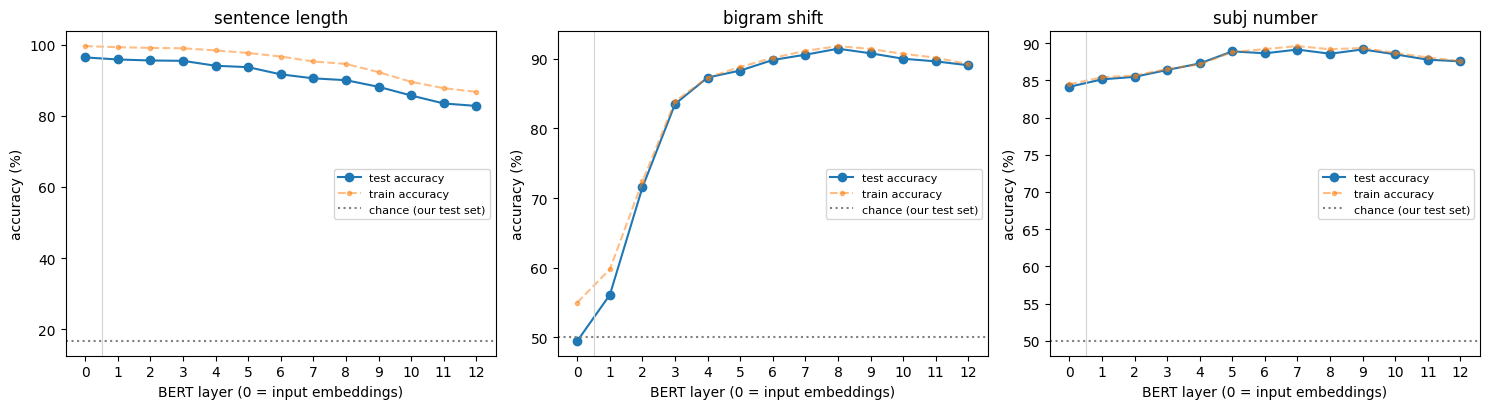

In [9]:
if os.path.exists(RESULTS_PATH):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=False)
    for ax, task in zip(axes, TASKS):
        layers = [r["layer"] for r in res[task]["layers"]]
        test = [100 * r["test_acc"] for r in res[task]["layers"]]
        train = [100 * r["train_acc"] for r in res[task]["layers"]]
        ax.plot(layers, test, marker="o", label="test accuracy")
        ax.plot(layers, train, marker=".", linestyle="--", alpha=0.5, label="train accuracy")
        ax.axhline(100 * res[task]["chance_test"], color="gray", linestyle=":", label="chance (our test set)")
        ax.axvline(0.5, color="lightgray", linewidth=0.8)
        ax.set_title(task.replace("_", " "))
        ax.set_xlabel("BERT layer (0 = input embeddings)")
        ax.set_xticks(layers)
        ax.set_ylabel("accuracy (%)")
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(f"{OUT}/probe_layers_{TAG}.png", dpi=150)
    plt.show()


### Paper comparison and interpretation

**Results** (excluding `[CLS]`/`[SEP]`, the main run). All 39 logistic-regression fits converged (57–298 iterations, limit 5000).

| Task | Chance (our test set) | Paper best (LR, Table 4) | Paper untrained BiLSTM-max | Ours: best layer | Ours: layer 0 (embeddings) | Ours: layer 12 |
|---|---|---|---|---|---|---|
| Sentence length | 16.7 | 94.5 (GatedConvNet, Seq2Tree) | 66.2 | 95.8 (layer 1) | 96.4 | 82.8 |
| Bigram shift | 50.0 | 80.9 (GatedConvNet, Seq2Tree) | 70.3 | 91.5 (layer 8) | 49.5 | 89.1 |
| Subject number | 50.0 | 91.8 (BiLSTM-max, Seq2Tree) | 84.6 | 89.1 (layer 9) | 84.1 | 87.5 |

**Chance differs from the paper.** The paper's majority vote for sentence length is 20.0, but a balanced six-class task
has a chance level of 16.7. That suggests the paper's classes were not balanced, so its majority-vote figure is not directly
comparable to ours.
The chance level used here is computed from our own test set.

**Shape of the layer curves.**
- *Sentence length* declines with depth, from 95.8 at layer 1 to 82.8 at layer 12. This is the expected direction.
- *Bigram shift* is at chance at the embedding layer (49.5). A mean over static word and position vectors cannot see word
  order, and the signal appears in layers 2–3 (71.5 and 83.5). It peaks at layer 8 (91.5) and falls slightly after that.
  Word order is therefore built up by the contextual layers, as expected.
- *Subject number* peaks at layer 9 (89.1). The embedding layer already reaches 84.1, so number is largely marked lexically
  (plural nouns, verb agreement). The contextual layers add about five points.

**Comparison with the paper.** Ours is not an identical protocol: the paper's encoders are not BERT, the paper uses its
own splits, and our test sets have 5,000 examples. The comparison is therefore a reference, not a target.
- Sentence length: BERT's best layer (95.8) is at the paper's best encoder (94.5).
- Bigram shift: the best BERT layer (91.5) is about 11 points above the paper's best encoder (80.9).
- Subject number: the best BERT layer (89.1) is 2.7 points below the paper's best (91.8), and well above the untrained
  BiLSTM-max (84.6).

**Sentence length needs care.** The embedding layer reaches 96.4%, which means the length signal does not come from
contextual processing. The likely source is the positional embeddings. Two checks support this:
- Mean-pooled word embeddings with the special tokens excluded, and no positional information, give 55.9%. The paper's
  bag-of-vectors baseline is 54.8%, so the check is consistent with the paper.
- Mean-pooled position embeddings alone give 85.8% (special tokens included).

So the high sentence-length accuracy here reflects positional information that survives mean pooling into every layer. It
is not evidence that BERT represents sentence length in a linguistic sense.

**Correction to the earlier version of this analysis.** Earlier I said that including `[CLS]`/`[SEP]` had inflated the
sentence-length results. The ablation does not support that as the main effect. The two pooling choices differ by at most
1.7 points on any layer (below), and the layer curves keep the same shape. The effect was real on word embeddings alone
(91.8% vs 55.9%), but it is small in the full model.

**Pooling ablation** (test accuracy, excluding minus including `[CLS]`/`[SEP]`, percentage points):

| Layer | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Sentence length | +0.0 | +0.2 | +0.0 | −0.2 | −0.5 | −0.6 | −0.6 | −0.7 | −0.9 | −0.6 | −1.7 | −1.5 | −1.1 |
| Bigram shift | −0.7 | −0.4 | +0.0 | +0.3 | +0.2 | −0.1 | +0.0 | +0.1 | +0.1 | +0.0 | +0.0 | +0.0 | +0.1 |
| Subject number | +0.1 | +0.0 | −0.1 | +0.1 | −0.0 | +0.1 | +0.1 | −0.1 | −0.3 | +0.0 | +0.0 | +0.1 | +0.1 |

**Caveats.**
- One seed for the data sampling and split. The logistic regression is deterministic given the data.
- The logistic regression uses sklearn's default regularisation (C = 1) with standardised features. No tuning was done.
- The paper's numbers are for different encoders, so they are reference points rather than targets.
- The probing data is the SentEval data, re-split by us from the pooled splits. This makes our numbers comparable to each
  other, not to the paper's table row for row.